# In-Class Assignment: Graph Theory
# Day 10
# CMSE 202

<img width=700px src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/journal.pone.0250212.g007.PNG" alt="A directed network graph of popular-music genres, where each node is a genre (such as Pop/Rock, Jazz, R&B, Country) sized by its prominence and colored by cluster, and arrows show cover-version relationships between genres.">
<br>
<p style="text-align: left;">
Figure from:  Ortega JL (2021) Cover versions as an impact indicator in popular music: A quantitative network analysis. PLoS ONE 16(4): e0250212. https://doi.org/10.1371/journal.pone.0250212
</p>

### <p style="text-align: right;"> &#9989; Dhruti Bhat </p>

## Learning goals for today's class

By the end of today's class, you should be able to:

1. Describe a graph/network in terms of its nodes (vertices) and edges.
1. Represent a graph as an adjacency matrix or an adjacency list.
1. Use the `networkx` package to construct, draw, label, and color graphs.
1. Recognize and reason about graph properties such as planarity and isomorphism.

### How this connects to the course learning goals

Beyond today's specific goals above, this assignment builds toward these **course-level learning goals** (see the syllabus, or the Day 1 notebook, for the full CLG 1-7 list):

- **CLG 2 - Identify and use pre-existing tools and code:** you'll learn to use the `networkx` package -- a new Python object with its own attributes and methods -- to build and draw graphs.
- **CLG 3 - Use appropriate data types, data structures, and algorithms:** you'll work with adjacency matrices and lists and explore graph concepts like planarity, isomorphism, and graph coloring.
- **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll visualize graphs with different layouts, labels, and colorings.
- **CLG 1 - Design and write programs to solve problems:** you'll write code to construct and draw several graphs.
- **CLG 6 - Work in diverse groups:** you'll discuss, draw, and problem-solve with your group throughout.

### Agenda for today's class

1. [Review of pre-class assignment](#pca-review)
1. [Getting familiar with graphs](#graphs)
1. [Working with networkx](#networkx)


---
<a id="pca-review"></a>
## 1. Pre-class assignment review and discussion

Did anyone have any specific issues with the pre-class assignment?

Let's take a moment to highlight some key concepts. **Discuss with your group** the following prompts and write down a some brief notes from your discussion.

&#9989; **Question 1:** What are the main two components of a graph/network?

<font size=+3>&#9998;</font> the nodes and the edges

&#9989; **Question 2:** Can you think of some examples of systems or data that could be well-represented using a graph? What data or components of the system would be represented by different parts of the graph?

<font size=+3>&#9998;</font> a social media system could be represented through a graph by having the nodes be users 

----
<a id="graphs"></a>
## 2. Getting familiar with graphs

### Seven Bridges of Königsberg

The city of Königsberg in Prussia (now Kaliningrad, Russia) is set on both sides of the Pregel River, and includes two large islands which are connected to each other and the mainland by seven bridges. The problem to be solved is to devise a walk through the city that would cross each bridge once and only once, with the provisos that: the islands could only be reached by the bridges and every bridge once accessed must be crossed to its other end. The starting and ending points of the walk need not be the same. 

<img src="https://upload.wikimedia.org/wikipedia/commons/5/5d/Konigsberg_bridges.png" alt="A historical map of Konigsberg showing the Pregel River, its two islands, and the seven bridges that connect the islands to each other and to the two river banks.">

&#9989; **Do This** - Using a piece of paper or whiteboard, layout this problem as a graph with nodes (land masses) and edges (bridges). **Talk with your group to see if you agree on how it should be represented.**

&#9989; **Do This** - Then, using your paper or virtual whiteboard, write out a representation of your graph as both an adjacency list and an adjacency matrix. **Talk with your group to see if you agree on how it should be represented.**

&#9989; **Do This** - Draw your solution to the Seven Bridges of Königsberg on your graph using a different color dry erase marker. If you can't seem to find a solution, be prepared to explain why. **Discuss your solution, or lack of solution, with your group.**

After all groups have a chance to think this through, **we will have a classroom wide discussion about this problem**.

---
### Sprouts

This activity introduces you to some aspects of graph theory via a game played by drawing graphs on a sheet of paper. The game is called "sprouts" and it is an invention of John Horton Conway and Michael S. Paterson at Cambridge University in the early 1960s.

Sprouts is a game played by two players, using a sheet of paper and a pen or a pencil. The game begins with a choice by the players of a collection of n "spots" or "nodes" on the paper. For example, here is a game board with n=3 (images and instructions from https://blog.doublehelix.csiro.au/game-sprouts/):

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/sprouts_1_start.jpg" alt="A Sprouts game board at the start: three green spots (nodes) drawn on paper with no connecting lines.">


1. On your turn, draw a line from one spot to another spot.
1. When you finish drawing your line, put a spot somewhere along its length, splitting the line in two. There are two rules you need to follow:
    * A line can’t cross over itself or other lines.
    * A spot can only have three lines coming out of it.
1. Once you finish your turn, it is your opponent’s turn. Keep alternating turns until it is impossible to draw a line. Whoever played the last move wins!

Here is the same board after one move:
<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/sprouts_2_one_move.jpg" alt="The same Sprouts board after one move: a curved line connects two of the spots, with a new spot added partway along it.">

Here is an example, completed, game with no more possible moves:
<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/sprouts_3_completed.jpg" alt="A completed Sprouts game: several curved lines connect the spots and no legal moves remain.">

&#9989; **Do This**: Within your group, find a partner and play the game. **You should find some whiteboard space to use or a sheet of paper**. 

Think about how you could represent the game in a program. Discuss your thoughts with other pairs in your group.

Also, **discuss anything learned about the game in terms of the maximum number of possible moves or the stategies for winning.**

**Decide on one or two people in your group who will share your thoughts with the class.**

---
<a id="pca-networkx"></a>
## 3. Working with Networkx

In this part of the activity, we will explore a package called [**_networkx_**](https://networkx.org/) which can be used to construct graphs in python.

### Using the networkx documentation

Navigating the networkx [documentation](https://networkx.org/documentation/stable/) can be somewhat unintuitive at times, so we have tried to provide you with some direct links to documentation pages on some of the more useful functions. At the top of this list are the `Graph()` constructor and the `draw()` function, so we've provided a couple of direct links to these tools.

#### Quick access resources

___
The `Graph()` constructor automatically calls a variety of functions which will convert other data formats like a dictionary or a numpy matrix into a networkx graph. Information about supported formats can be found here https://networkx.org/documentation/stable/reference/convert.html. Hopefully this activity will give you a chance to practice building graphs in a variety of ways. After we build a graph object, the first thing we want to do is visualize it. The best way to do this is usually the `draw()` function. The different parameters we can use for the draw function are found here:

https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx.html#networkx.drawing.nx_pylab.draw_networkx

Even though this page is for the `draw_networkx()` function, all of these parameters can be used inside the `draw()` function as well.
___




To begin, we will consider an example from a special family of graphs called the **_complete graphs_.** A complete graph has the property that each node is connected to every other node. The complete graph with _n_ nodes is usually denoted by $K_n$. One nice property of the complete graphs is that they have a very simple adjacency matrix (what is it?). We can use a NumPy (adjacency) matrix to build a graph by passing it directly to the networkx `Graph()` constructor. The `Graph()` constructor is the prefered way of creating all graphs in networkx. As long as the input object is in a supported format, the `Graph()` constructor will automatically call the proper function to convert your object into a networkx graph. We can then draw a graph by passing our graph object to the networkx `draw()` function. Let's test it out!

### **Part 1:**

&#9989; **In the cell below, create an adjacency matrix for the complete graph, $K_4$ (4 nodes with each node connected to every other node), using a numpy array. Then create a networkx graph using the `Graph()` constructor and plot it out using the `draw()` function.**

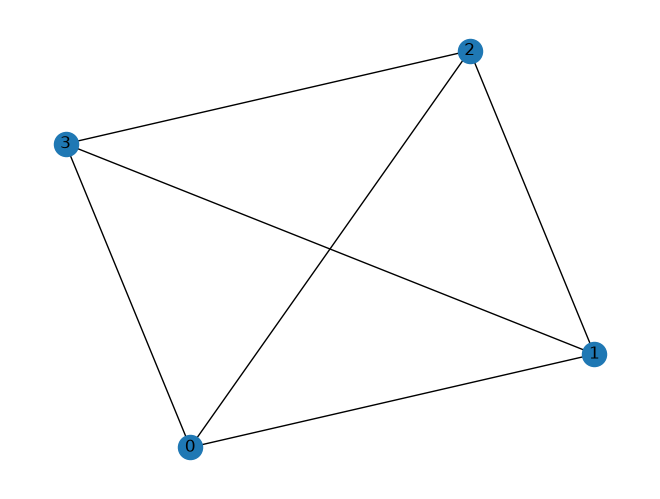

In [2]:
# Put your code hereimport numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

A = np.array([[0, 1, 1, 1], [1, 0, 1, 1], [1, 1, 0, 1], [1, 1, 1, 0]])
G = nx.Graph(A)
nx.draw(G, with_labels=True)


&#9989; **Read this:** In the graph you made for $K_4$ above, you may notice that if you run the cell repeatedly, the position of the nodes changes. Another thing to notice is that the graph $K_4$ has been drawn so that two of its edges intersect in the center. Neither of these behaviors are especially desirable. To remedy this, the networkx draw function has a `pos` parameter which can be used to fix the positions of the nodes in place. To use it, we'll need to create a dictionary containing the names of the nodes as the keys, and the desired (x,y)-coordinates as values. Since we haven't given our nodes any names yet, they will be keyed by integer values by default.

### **Part 2:**

&#9989; **With your group, find a way to reposition the nodes of the graph $K_4$ so that the edges do not intersect. Create a dictionary, `positions`, representing your drawing. Pass your dictionary to the `pos` parameter in the networkx `draw()` function to reposition the nodes.**

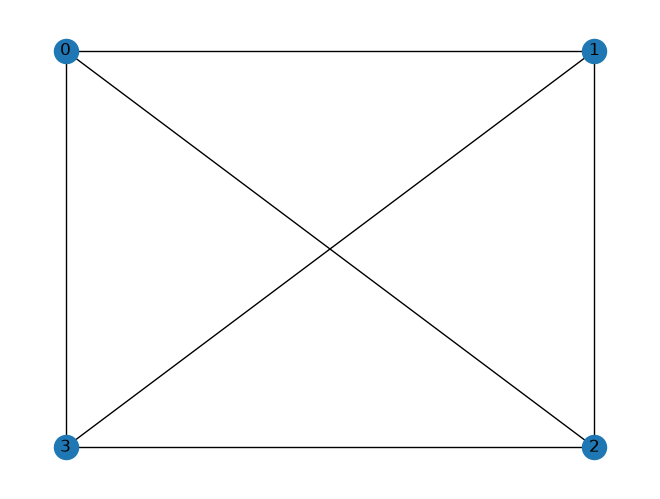

In [8]:
# Put your code here
positions = {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (0, 0)}
nx.draw(G, pos=positions, with_labels=True)

&#9989; **Read this**: The `pos` parameter is a central tool for understanding graphs with networkx. You just proved that it could be used to draw $K_4$ so that it does not intersect, and since $K_4$ is small, it is fairly easy for us to see that the two drawings represent the same graph. However, as the number of nodes and edges grow large, it becomes increasingly difficult to decide whether or not two drawings represent the same graph. In technical languange, two graph drawings that have the same nodes with the same edge connections between them are called **_isomorphic_**. If a graph drawing is isomporphic to another graph drawing but does not have any intersecting edges, we call the graph **_planar_**. As you just worked out with your group, the complete graph $K_4$ is a planar graph. Lets see a more complicated example of isomorphic graph drawings.

#### Example: Dodecahedral Graph

&#9989; Run the code below to see four different representations of the same dodecahedral graph.

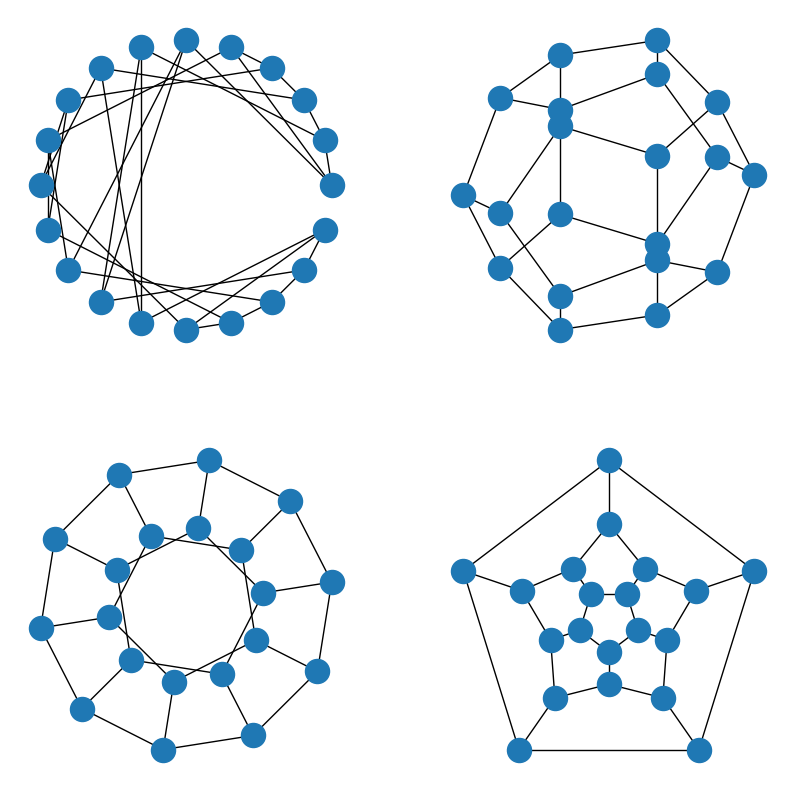

In [4]:
## Positions for a planar drawing called a Schlegel Diagram.
pos_dodecahedron = {0: (1.1888206453689418, 0.38627124296868426), 1: (7.654042494670958e-17, 1.25), 2: (-1.1888206453689418, 0.38627124296868437), 3: (-0.7347315653655916, -1.011271242968684), 4: (0.7347315653655911, -1.0112712429686845), 5: (0.7132923872213651, 0.23176274578121053), 6: (4.592425496802574e-17, 0.75), 7: (-0.7132923872213651, 0.23176274578121064), 8: (-0.4408389392193549, -0.6067627457812105), 9: (0.4408389392193547, -0.6067627457812107), 10: (-0.4755282581475768, -0.15450849718747364), 11: (-9.184850993605148e-17, -0.5), 12: (0.47552825814757677, -0.1545084971874738), 13: (0.2938926261462367, 0.4045084971874736), 14: (-0.29389262614623646, 0.40450849718747384), 15: (-0.2377641290737884, -0.07725424859373682), 16: (-4.592425496802574e-17, -0.25), 17: (0.23776412907378838, -0.0772542485937369), 18: (0.14694631307311834, 0.2022542485937368), 19: (-0.14694631307311823, 0.20225424859373692)}

nodes_dodecahedron = pos_dodecahedron.keys()
edges_dodecahedron = [(0,1), (1,2), (2,3), (3,4), (4,0),
                     (0,5), (1,6), (2,7), (3,8), (4,9),
                     (6,14), (14,7), (7,10), (10,8), (8,11),
                     (11,9), (9,12), (12,5), (5,13), (13,6),
                     (10,15), (11,16), (12,17), (13,18), (14,19),
                     (15,16), (16,17), (17,18), (18,19), (19,15)]

## You can also leave the arguemnt of the Graph() constructor empty
dodecahedron = nx.Graph()
## Then add nodes from a nodelist
dodecahedron.add_nodes_from(nodes_dodecahedron)
## Then add edges from an edgelist
dodecahedron.add_edges_from(edges_dodecahedron)

## Networkx offers different algorithms to decide how to draw a graph
## The different options can be found under 'layout'
pos1 = nx.layout.circular_layout(dodecahedron)
pos2 = nx.layout.spectral_layout(dodecahedron)
pos3 = nx.layout.kamada_kawai_layout(dodecahedron)

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10,10))
nx.draw(dodecahedron, pos=pos1, ax=ax[0,0])
nx.draw(dodecahedron, pos=pos2, ax=ax[0,1])
nx.draw(dodecahedron, pos=pos3, ax=ax[1,0])
nx.draw(dodecahedron, pos=pos_dodecahedron, ax=ax[1,1])

&#9989; **Read this:** The four drawings of the dodecahedral graph shown above are just a small sample from the pool of possibilities. Additional drawings, some of which are quite striking, can be found here http://mathworld.wolfram.com/DodecahedralGraph.html. The dodecahedral graph is a good demonstration that even a moderate increase in the number of nodes and edges can seriously complicate the task of determing whether or not two drawings are isomorphic. However if you are left with any doubt that these drawings really are the same graph, verify it!

You can turn on node labels by setting the **`with_labels`** parameter to `True` inside the draw function. Choose any node you like, and take note of the "neighbor" nodes that connected to it. You will find that for any node you choose, its neighbors will be the same in all four graph drawings! You may also find it useful to color the nodes. Networkx has a function called **`greedy_color()`** which will automatically assign the nodes a **_proper coloring_** with the minimum number of colors necessary. A proper coloring gives colors to the nodes so that no two neighbors are the same color. To be specific, the `greedy_color()` function takes the desired networkx graph as its input, and outputs a dictionary. Note that the keys of that dictionary contain the names of the nodes and the value associated with each key is a single integer for each node. Therefore, **the list of colors you need for coloring the nodes are the "values" in the dictionary that comes from `greedy_color`, which are accessible using the `.values()` method.**

Here's an example of how you could use the `greedy_color()` function for the graph `G`.

> ```python
> node_map = nx.greedy_color(G)
> node_colors = list(node_map.values())
> cmap = 'viridis'
> nx.draw(G,node_color=node_colors, cmap=cmap, with_labels=True)
> ```


Many different colormap options are available from matplotlib, some of which can be found here https://matplotlib.org/stable/gallery/color/colormap_reference.html. If you don't want to choose a colormap, that's okay too. If you do not change the `cmap` parameter then the `draw()` function will simply use default colors. However, make sure you still pass the integer list into the `node_color` parameter.

### **Part 3:**
&#9989; **Try modifying the dodecahedron example so that the nodes are assigned a proper coloring. Also, turn on the node labels and change the font color if necessary so we can see them.** Figuring out how to properly pass color information to the networkx graph can be a little tricky, so review the example code above and check in with your group to figure this out!

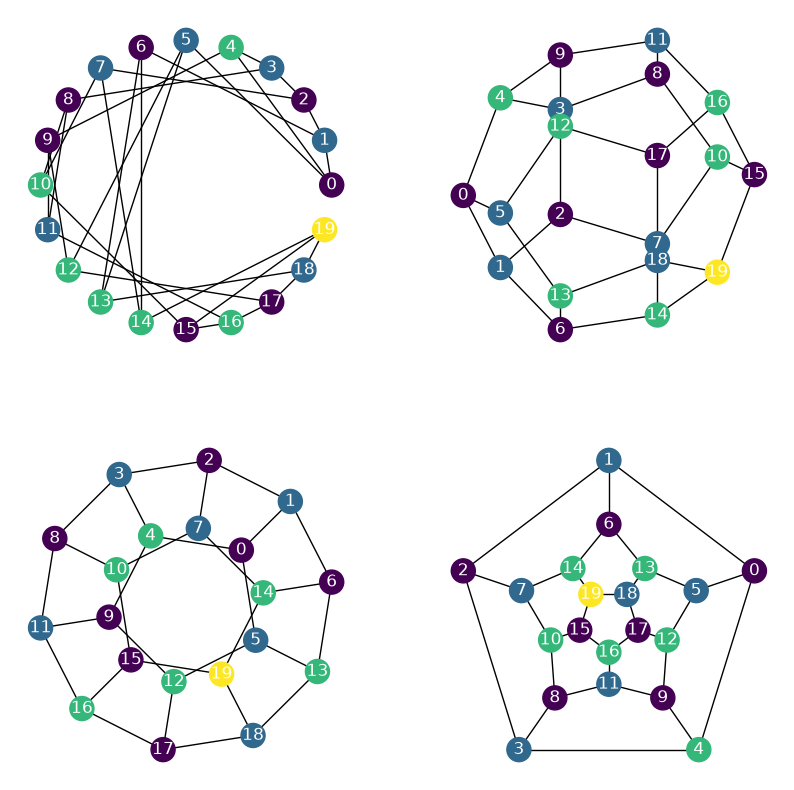

In [10]:
### Copy the above code and modify it here
node_map = nx.greedy_color(dodecahedron)
node_colors = list(node_map.values())
cmap = 'viridis'
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10,10))

nx.draw(dodecahedron, pos=pos1, ax=ax[0,0], node_color=node_colors, cmap=cmap, with_labels=True, font_color='white')
nx.draw(dodecahedron, pos=pos2, ax=ax[0,1], node_color=node_colors, cmap=cmap, with_labels=True, font_color='white')
nx.draw(dodecahedron, pos=pos3, ax=ax[1,0], node_color=node_colors, cmap=cmap, with_labels=True, font_color='white')
nx.draw(dodecahedron, pos=pos_dodecahedron, ax=ax[1,1], node_color=node_colors, cmap=cmap, with_labels=True, font_color='white')

&#9989; **Read this:** Labels are an extremely useful tool for understanding graphs, so we'll want to know how to leverage the `Graph()` constructor to make use of them. The best way to construct a labeled graph is to pass a labeled object to the `Graph()` constructor.

For example, **one way to construct a labeled graph is to first create a labeled adjacency matrix using a Pandas dataframe**. Your dataframe should contain the same data as the adjacency matrix, with both the columns and the index set to the list of node labels you want to use. You can create a labeled graph by passing in the dataframe the same way you pass in a regular adjacency matrix. However this is just one way to construct a graph using the `Graph()` constructor.

**Another method which can be used to build the same labeled graph is to first build an adjacency list**. We can implement an adjacency list in python using a dictionary object. Each key in the dictionary should be the name of a node and its value should be a list containing the names of the neighbors of that node.

These are just two examples, but there are many more ways of building graphs in networkx. Feel free to explore the networkx documentation and make sure you find a method for constructing graphs which makes sense to you! Information about some of the different methods which can be called automatically by the `Graph()` constructor can be found on the following documentation page (the same one found in the resource section) https://networkx.org/documentation/stable/reference/convert.html.

### **Part 4:**

&#9989; **In the cell below, create and draw the complete graph, $K_5$, with node labels 'A', 'B', 'C', 'D' and 'E'. Make sure the node labels are turned on in the drawing. Feel free to test out any other features of networkx you are interested in.**

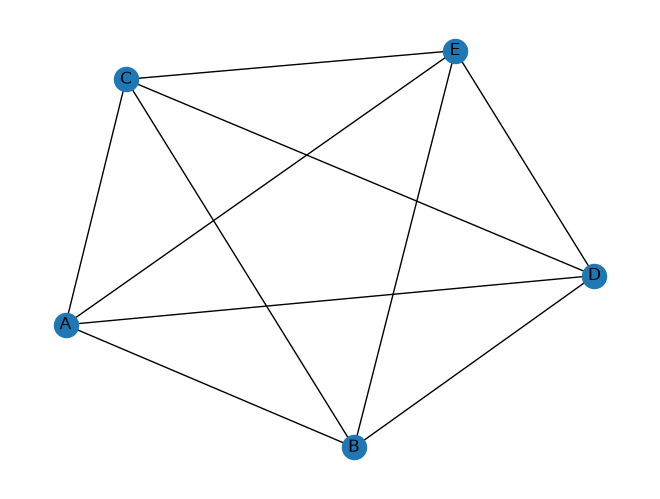

In [11]:
# Put your code here
K5 = nx.complete_graph(['A', 'B', 'C', 'D', 'E'])
nx.draw(K5, with_labels=True)

&#9989; **Read this**: The graph $K_5$ is different from our first two examples. Your group has already shown that the graph $K_4$ is planar. In addition, the graph drawn in the bottom right corner of the example given above demonstrates that the dodecahedral graph is also planar. In constrast, the graph $K_5$ **_is not planar_**. This means that **_there does not exist_** a drawing of the graph $K_5$ without at least one edge intersection. It may seem that worrying about whether or not a graph has edge intersections is trivial, however it does have real consequences.

#### Consider the following scenario:

> *There is a new city being built and you are its architect. The citizens funding the project are especially safety conscious so they have given you requirements as to how the major roads need to be laid out in order for the police station, fire department, and hospital to have the most direct routes possible in the event of an emergency. The city will have three predominant metropolitan areas: a park, a sports stadium, and a museum. Your job is to arrange the city so that each of the major metropolitan areas has a direct route along a major road to the hospital, police station, and fire department. In order to prevent any conflicts from arising between the three, the routes should not intersect. Can you meet the needs of the safety conscious citizens?*

### **Part 5:**
&#9989; **In the cell below, create a graph representing this scenario. Explore different ways to represent elements of the problem using the available features of networkx Graphs and graph drawing. If you want some inspiration, check out the networkx examples page https://networkx.org/documentation/stable/auto_examples/index.html**

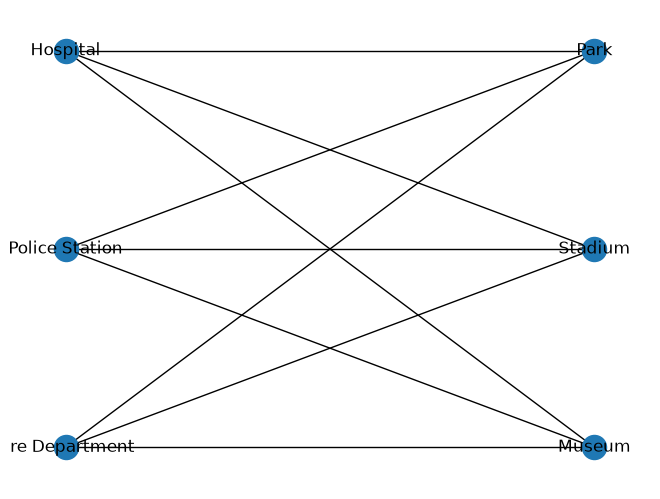

In [13]:
# Put your code here
city = nx.Graph()
emergency = ['Hospital', 'Police Station', 'Fire Department']
areas = ['Park', 'Stadium', 'Museum']
city.add_nodes_from(emergency)
city.add_nodes_from(areas)

for e in emergency:
    for a in areas:
        city.add_edge(e, a)

pos = {'Hospital': (0, 2), 'Police Station': (0, 1), 'Fire Department': (0, 0), 'Park': (2, 2), 'Stadium': (2, 1), 'Museum': (2, 0)}
nx.draw(city, pos=pos, with_labels=True)

#### &#9989; Reflection:

Were you able to meet the demands of citizens? Explain why or why not in the cell below.

<font size=+3>&#9998;</font> i wasnt able to make the routes avoid intersections but i was able to make it somewhat efficient.

----

-----
### Congratulations, we're done!

Now, you just need to submit this assignment by uploading it to the course <a href="https://d2l.msu.edu/">Desire2Learn</a> web page for today's submission folder (Don't forget to add your name in the first cell).

&#169; Copyright 2026,  Department of Computational Mathematics, Science and Engineering at Michigan State University